# Physicochemical reconstruction of atom contributions

**Kind:** experiment. This notebook can run independently of training.

Fit the primary seven-descriptor Ridge model on all 23,029 MMPs using the
bundled R fold-0 AC table, or set `ATOM_CONTRIBUTIONS_PATH` to a newly trained
model's `atom_contributions.csv`. Reconstruction is in-sample on both endpoints;
it does not measure generalization to unseen atoms or causal effects.

**Executed notebook.** Local paths are displayed relative to the repository root; numerical outputs and figures are unchanged.


In [1]:
LOCAL_PROJECT_ROOT = "."
ATOM_CONTRIBUTIONS_PATH = "sglt2_data/reference_R_ac.csv.gz"
RIDGE_ALPHA = 1.0

## 1. Runtime and reference inputs

In [2]:
from pathlib import Path
import os
import sys
import json
from IPython.display import display

# Use the declared repository root in both Colab and local execution.
try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    IS_COLAB = False
else:
    IS_COLAB = True
ROOT = Path(os.environ.get("XAI_CHEM_ROOT", LOCAL_PROJECT_ROOT)).expanduser().resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print({"runtime": "colab" if IS_COLAB else "local", "root": str(ROOT), "python": sys.executable})

# Numerical tables, chemistry figures, and explicit CPU execution.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)
%matplotlib inline


{'runtime': 'local', 'root': '.', 'python': 'python'}


## 2. Bind the seven raw descriptors and the selected teacher

In [3]:
from xai_chem.reconstruction import load_mmp_inputs, fit_all_mmp_pairs

DESCRIPTORS = (
    "crest_boltzmann_weighted_displacement_A", "hessian_rmsf_A",
    "fukui_plus_raw", "fukui_minus_raw", "neutral_charge_square",
    "epsilon_kcal_mol", "sigma_angstrom",
)
teacher_path = ROOT / ATOM_CONTRIBUTIONS_PATH

mmp_rows, atom_rows = load_mmp_inputs(
    mmp_path=ROOT / "sglt2_data/sglt2_reconstruction_mmp.csv.gz",
    descriptor_path=ROOT / "sglt2_data/sglt2_descriptors.csv.gz",
    dataset_path=ROOT / "sglt2_data/sglt2.csv",
    teacher_path=teacher_path, teacher_fold=None, descriptor_columns=DESCRIPTORS,
)
display(atom_rows[["graph_id", "atom_idx", *DESCRIPTORS, "atom_contribution"]].head())
print({"teacher_path": str(teacher_path), "pairs": len(mmp_rows), "atoms": len(atom_rows), "ridge_alpha": RIDGE_ALPHA})

,graph_id,atom_idx,crest_boltzmann_weighted_displacement_A,hessian_rmsf_A,fukui_plus_raw,fukui_minus_raw,neutral_charge_square,epsilon_kcal_mol,sigma_angstrom,atom_contribution
0,0,0,5.234355,0.525772,-0.032154,-0.023367,0.007550,0.141568,2.997966,0.268868
1,0,1,2.961975,0.340369,-0.007911,-0.022662,0.001808,0.268136,3.396290,0.297270
2,0,2,2.033429,0.410464,-0.015501,-0.019290,0.002157,0.052803,2.835060,0.147006
3,0,3,1.286064,0.235564,-0.002571,-0.016460,0.025333,0.085326,3.033377,0.136723
4,0,4,1.227000,0.271786,-0.012030,-0.011881,0.001571,0.052803,2.835060,0.010386


{'teacher_path': 'sglt2_data/reference_R_ac.csv.gz', 'pairs': 23029, 'atoms': 39530, 'ridge_alpha': 1.0}


## Physicochemical reading guide

These are model-derived descriptors, averaged over each heavy atom and its bonded hydrogens; they are not bare-heavy-atom values.

| Descriptor | Physical interpretation |
|---|---|
| CREST displacement (Å) | Larger: broader sampled conformational spread relative to the lowest-energy conformer (Boltzmann weights, 298.15 K). |
| Hessian RMSF (Å) | Larger: softer local motion around one optimized minimum (harmonic approximation, 300 K). |
| Fukui f⁺ | More negative here: greater estimated electron gain upon electron addition; an electron-accepting/electrophilic-region proxy. |
| Fukui f⁻ | More negative here: greater estimated electron loss upon electron removal; an electron-donating/nucleophilic-region proxy. |
| Neutral charge² (e²) | Larger: greater local partial-charge magnitude; charge sign is lost. |
| OpenFF LJ ε (kcal/mol) | Assigned Lennard–Jones well-depth scale, used as a dispersion-interaction proxy. |
| OpenFF LJ σ (Å) | Assigned Lennard–Jones size/repulsion length scale, used as a steric-size proxy. |

**Fukui signs:** stored net-charge differences have the opposite sign to the usual electron-population convention. Averaged ε/σ are parameter proxies, not an effective pair potential or measured binding energies. See the [Fukui definitions](https://www.scm.com/doc/GUI/Fukui.html) and [Lennard–Jones parameter definitions](https://docs.openforcefield.org/projects/toolkit/en/0.2.0/smirnoff.html).

First check reconstruction fidelity. Then read signed descriptor effects: positive/negative B−A effects raise/lower B's reconstructed **changed-region AC sum** relative to A. Read these effects together with raw descriptor maps; a high raw value alone does not imply a positive AC or a favorable effect. Correlated descriptors can share explanatory weight, so the result describes pair-local model evidence, not a causal mechanism. For SGLT2, higher pIC50 means lower IC50 (greater inhibitory potency).


## 3. Pairwise standardization, fit, and exact effects

For each pair, fit the descriptors and atom labels of its A/B changed-region atoms:

$$
z_{id}=\frac{x_{id}-\mu_{d,AB}}{s_{d,AB}},\qquad
\tilde c_i=\frac{c_i-\bar c_{AB}}{s_{c,AB}}.
$$

`fit_pair` solves Ridge with `fit_intercept=False` in this standardized space:

$$
\hat\beta=\mathop{\arg\min}_{\beta}\left\lVert\tilde c-Z\beta\right\rVert_2^2+\alpha\lVert\beta\rVert_2^2,
\qquad e_{id}=s_{c,AB}z_{id}\hat\beta_d.
$$

The endpoint difference contains both the exact descriptor effects and the
intercept-sum term $(n_B-n_A)\bar c_{AB}$. Atom-count difference is not a fitted descriptor.
Zero descriptor variance uses StandardScaler's unit scale; constant labels use
the existing unit-scale convention. No augmentation is used.

In [4]:
variants = {"ridge": {"model_kind": "ridge", "alpha": RIDGE_ALPHA, "augmentation_multiplier": 0}}
all_fit = fit_all_mmp_pairs(mmp_rows, atom_rows, variants=variants, descriptors=DESCRIPTORS)
display(all_fit.audit.head())
display(all_fit.fit_metrics.head())
display(all_fit.coefficients.head(14))
display(all_fit.concept_deltas.head(14))

,pair_id,document_id,mmp_class,molecule_A,molecule_B,n_diff_atoms_A,n_diff_atoms_B,n_diff_atoms_total,n_missing_descriptor_atoms,n_missing_teacher_atoms,fit_status,fit_eligible
0,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,9,10,19,0,0,eligible,True
1,1,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0972,9,8,17,0,0,eligible,True
2,2,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0996,9,10,19,0,0,eligible,True
3,3,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0997,9,9,18,0,0,eligible,True
4,4,CHEMBL1139015,single_cut,sglt2_0923,sglt2_0972,10,8,18,0,0,eligible,True


,pair_id,document_id,mmp_class,molecule_A,molecule_B,variant,model_kind,augmentation_method,n_original_atoms,n_training_rows,...,atom_mae_in_sample,atom_nrmse_by_pair_sd,atom_pearson_r_in_sample,atom_spearman_r_in_sample,teacher_delta_B_minus_A,fitted_delta_B_minus_A,delta_residual,abs_delta_error,delta_direction_match,experimental_delta_pIC50_B_minus_A
0,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,ridge,ridge,none,19,19,...,0.014120,0.657613,0.755292,0.673684,-0.075458,-0.118300,0.042842,0.042842,True,-0.702574
1,1,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0972,ridge,ridge,none,17,17,...,0.011760,0.430282,0.905118,0.812998,-0.312488,-0.272524,-0.039964,0.039964,True,-0.831976
2,2,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0996,ridge,ridge,none,19,19,...,0.020046,0.496353,0.873160,0.794737,-0.450250,-0.490107,0.039857,0.039857,True,-0.922985
3,3,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0997,ridge,ridge,none,18,18,...,0.014960,0.599971,0.802105,0.740703,-0.304568,-0.125875,-0.178693,0.178693,True,-0.925140
4,4,CHEMBL1139015,single_cut,sglt2_0923,sglt2_0972,ridge,ridge,none,18,18,...,0.012881,0.741830,0.676354,0.432628,-0.237030,-0.069102,-0.167928,0.167928,True,-0.129402


,pair_id,document_id,variant,descriptor,model_kind,n_basis,ridge_coefficient_scaled_y,effect_per_descriptor_sd,raw_slope,basis_coefficient_l2,effect_mean_abs,effect_rms,abs_effect_per_descriptor_sd
0,0,CHEMBL1139015,ridge,crest_boltzmann_weighted_displacement_A,ridge,1,-0.417262,-0.010836,-0.010738,0.010836,0.009649,0.010836,0.010836
1,0,CHEMBL1139015,ridge,hessian_rmsf_A,ridge,1,-0.053641,-0.001393,-0.011521,0.001393,0.001112,0.001393,0.001393
2,0,CHEMBL1139015,ridge,fukui_plus_raw,ridge,1,0.082951,0.002154,0.341222,0.002154,0.001687,0.002154,0.002154
3,0,CHEMBL1139015,ridge,fukui_minus_raw,ridge,1,-0.276268,-0.007175,-0.826935,0.007175,0.006059,0.007175,0.007175
4,0,CHEMBL1139015,ridge,neutral_charge_square,ridge,1,0.206532,0.005364,0.628639,0.005364,0.003843,0.005364,0.005364
5,0,CHEMBL1139015,ridge,epsilon_kcal_mol,ridge,1,-0.051944,-0.001349,-0.063111,0.001349,0.001283,0.001349,0.001349
6,0,CHEMBL1139015,ridge,sigma_angstrom,ridge,1,-0.643819,-0.016720,-0.068436,0.016720,0.014726,0.016720,0.016720
7,1,CHEMBL1139015,ridge,crest_boltzmann_weighted_displacement_A,ridge,1,-0.683028,-0.023079,-0.029146,0.023079,0.021209,0.023079,0.023079
8,1,CHEMBL1139015,ridge,hessian_rmsf_A,ridge,1,0.474724,0.016041,0.174571,0.016041,0.009985,0.016041,0.016041
9,1,CHEMBL1139015,ridge,fukui_plus_raw,ridge,1,-0.025589,-0.000865,-0.165318,0.000865,0.000693,0.000865,0.000865


,pair_id,document_id,mmp_class,molecule_A,molecule_B,descriptor,delta_effect
0,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,shared atom bias,0.025654
1,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,crest_boltzmann_weighted_displacement_A,-0.178948
2,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,hessian_rmsf_A,-0.013796
3,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,fukui_plus_raw,0.002809
4,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,fukui_minus_raw,0.019938
5,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,neutral_charge_square,0.014203
6,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,epsilon_kcal_mol,-0.000831
7,0,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0923,sigma_angstrom,0.012672
8,1,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0972,shared atom bias,-0.014729
9,1,CHEMBL1139015,single_cut,sglt2_0673,sglt2_0972,crest_boltzmann_weighted_displacement_A,-0.360548


## 4. Audit coverage and exact reconstruction

In [5]:
metrics = all_fit.fit_metrics.set_index("pair_id")
effects = all_fit.concept_deltas.groupby("pair_id")["delta_effect"].sum()
reconstruction_gap = effects.loc[metrics.index].to_numpy() - metrics["fitted_delta_B_minus_A"].to_numpy()
print({"audited_pairs": len(all_fit.audit), "fitted_pairs": len(metrics),
       "max_exact_effect_gap": float(np.max(np.abs(reconstruction_gap))),
       "mean_atom_r2_in_sample": float(metrics["atom_r2_in_sample"].mean())})
np.testing.assert_allclose(reconstruction_gap, 0.0, atol=1e-10)
if len(metrics) != len(mmp_rows):
    raise ValueError("The canonical all-MMP population was not fully reconstructed")

output = ROOT / "notebooks_for_sglt2/output/reconstruction/csv"
output.mkdir(parents=True, exist_ok=True)
for filename, table in {"coverage": all_fit.audit, "metrics": all_fit.fit_metrics,
                        "coefficients": all_fit.coefficients, "exact_effects": all_fit.concept_deltas}.items():
    table.to_csv(output / f"{filename}.csv", index=False)


{'audited_pairs': 23029, 'fitted_pairs': 23029, 'max_exact_effect_gap': 1.3322676295501878e-15, 'mean_atom_r2_in_sample': 0.6036365040538471}


## 5. Inspect reconstruction fidelity

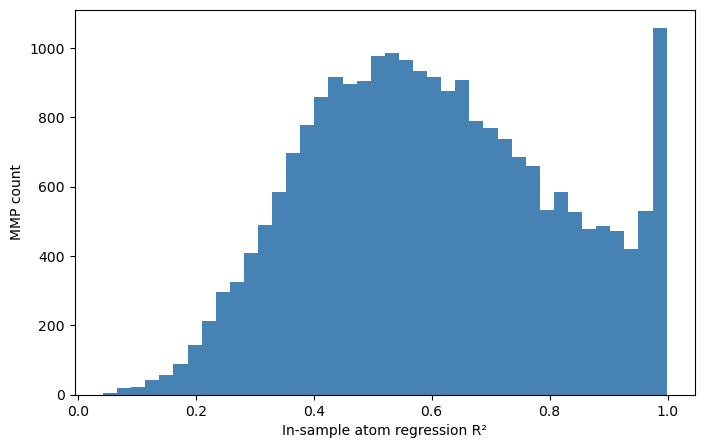

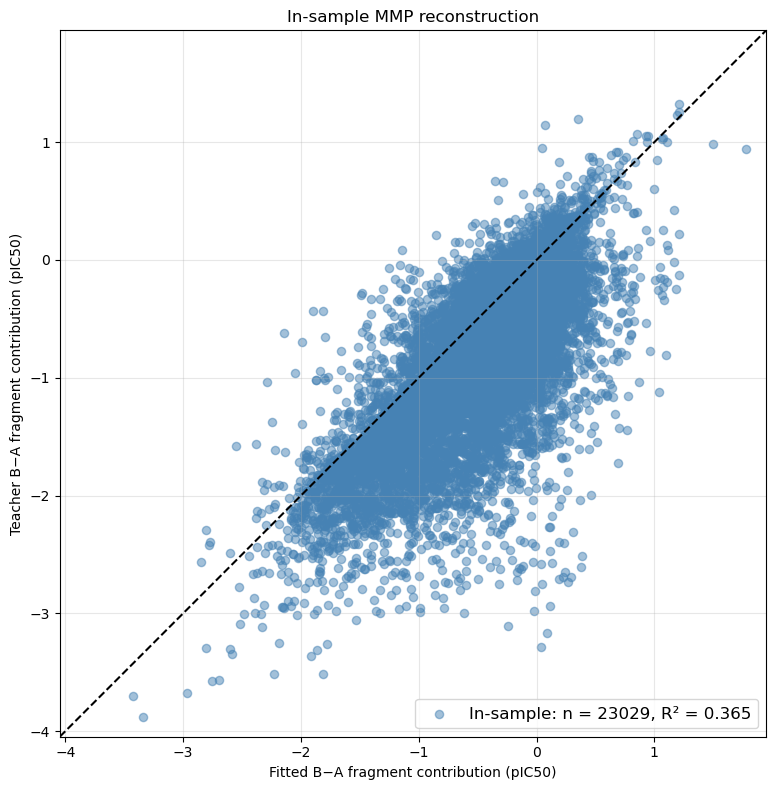

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,23029,0.450298,0.302396,0.364666,0.567208


In [6]:
from xai_chem.plotting import plot_reconstruction_yy, save_publication_figure
figure, axis = plt.subplots(figsize=(8, 5))
axis.hist(metrics["atom_r2_in_sample"], bins=40, color="steelblue")
axis.set(xlabel="In-sample atom regression R²", ylabel="MMP count")
save_publication_figure(figure, output.parent / "vis" / "atom_reconstruction_r2.png")
display(figure); plt.close(figure)
figure, scores = plot_reconstruction_yy(
    metrics["teacher_delta_B_minus_A"], metrics["fitted_delta_B_minus_A"],
    unit_label="B−A fragment contribution (pIC50)", title="In-sample MMP reconstruction",
)
save_publication_figure(figure, output.parent / "vis" / "delta_reconstruction_yy.png")
display(figure); plt.close(figure)
display(scores)


The fidelity plot measures reconstruction of a fixed teacher on the fitted atoms. It does not measure held-out predictive accuracy or establish causal descriptor effects. MMPs share atoms and molecules, so the 23,029 fits are not independent replicates. The original regularization, pair orientation, atom mapping, and raw physical descriptor values are preserved.